# Experiment 11: Width 512 at a lower learning rate

Card: [exp11_width_lr.md](../../experiments/exp11_width_lr.md)


In [1]:
import os
import sys
from time import perf_counter

import lightning.pytorch as L
from lightning.pytorch.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp11_width_lr"
EMB_DIM = 12  # picked in exp03
LR = 3e-3
if SMOKE:
    EXPERIMENT = "ashrae-mlp-width-lr-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 3
    WIDTH = 128  # the only width the exp10 smoke run trained
    # (experiment, session, width) of the reused runs at lr 1e-2; None: the latest session
    REFERENCES = [
        ("ashrae-mlp-width-smoke", None, WIDTH),
        ("ashrae-mlp-batch-norm-smoke", None, 64),
    ]
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-width-lr"
    TRAIN = False  # the runs below are from 2026-10-12; True resumes this session, retraining unfinished runs
    SESSION = "2026-10-12 23:17:08"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 40
    WIDTH = 512
    REFERENCES = [
        ("ashrae-mlp-width", "2026-10-12 22:43:11", WIDTH),  # exp10
        ("ashrae-mlp-batch-norm", "2026-10-12 21:52:51", 64),  # exp09
    ]
    FIGURE = "../../figures/exp11_width_lr.png"

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/12 23:17:09 INFO mlflow.tracking.fluent: Experiment with name 'ashrae-mlp-width-lr' does not exist. Creating a new experiment.


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-width-lr', session 2026-10-12 23:17:08


## Training


In [2]:
def at_best(run_id):
    """A run's scores at its best validation epoch and its per-epoch curves; a diverged run scores inf."""
    val = np.array(experiment.history(run_id, "val_rmsle"))
    train = np.array(experiment.history(run_id, "train_rmsle"))
    if not np.isfinite(val).all():
        return {"val": np.inf, "val_curve": val, "train_curve": train}
    b = int(val.argmin())
    return {
        "best_epoch": b + 1,
        "val": val[b],
        "val_clean": experiment.history(run_id, "val_rmsle_clean")[b],
        "train": train[b],
        "train_last": train[-1],
        "epoch_seconds": np.mean(experiment.history(run_id, "epoch_seconds")),
        "val_curve": val,
        "train_curve": train,
    }


def session_runs(name, session):
    """Finished runs of one session of another notebook (the latest one if `session` is None)."""
    runs = mlflow.search_runs(
        experiment_names=[name], filter_string="attributes.status = 'FINISHED'"
    )
    runs = runs.rename(columns=lambda c: c.removeprefix("tags."))
    return runs[runs.session == (session or runs.session.max())]


def scores():
    own = experiment.runs().rename(columns=lambda c: c.removeprefix("tags."))
    own = own[own.status == "FINISHED"].assign(
        width=WIDTH, lr=LR
    )  # an interrupted run is retrained
    refs = []
    for name, session, width in REFERENCES:
        ref = session_runs(name, session)
        ref = ref[ref["params.lr"].astype(float) == 1e-2]  # exp10 tags no lr
        if "width" in ref:  # exp09 trained width 64 only and has no width tag
            ref = ref[ref.width.astype(int) == width]
        refs.append(ref.assign(width=width, lr=1e-2))
    runs = pd.concat([own, *refs])[["run_id", "width", "lr", "fold"]]
    runs = (
        runs[runs.fold.isin(FOLD_NAMES)]
        .assign(width=lambda r: r.width.astype(int), lr=lambda r: r.lr.astype(float))
        .reset_index(drop=True)
    )
    scored = pd.DataFrame([at_best(r) for r in runs.run_id], index=runs.index)
    results = pd.concat([runs, scored], axis=1)
    results["minutes_to_best"] = results.epoch_seconds * results.best_epoch / 60
    return results


class CleanRMSLE(L.Callback):
    """Logs validation RMSLE on the clean rows after every epoch, so it can be read at the best epoch."""

    def __init__(self, loader, y):
        self.loader, self.y = loader, y

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("val_rmsle_clean", rmsle(self.y, predict(model, self.loader)))


class EpochSeconds(L.Callback):
    """Logs the wall time of each epoch's training batches, without validation."""

    def on_train_epoch_start(self, trainer, model):
        self.start = perf_counter()

    def on_validation_start(self, trainer, model):
        if not trainer.sanity_checking:
            self.seconds = perf_counter() - self.start

    def on_validation_epoch_end(self, trainer, model):
        if not trainer.sanity_checking:
            model.log("epoch_seconds", self.seconds)

In [ ]:
if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        clean = ~val_df.anomaly.to_numpy()
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "clean": (
                make_loaders(train_df, val_df[clean], X_train, X_val[clean])[1],
                np.log1p(val_df.meter_reading.to_numpy(dtype="float32")[clean]),
            ),
        }
    del df
    n_features = X_train.shape[1]
    done = set() if SESSION is None else set(scores().query("lr == @LR").fold)

    for fold, d in folds.items():
        if fold in done:
            continue
        experiment.fit(
            lambda: MeterMLP(
                n_features, n_buildings, emb_dim=EMB_DIM, batch_norm=True, width=WIDTH
            ),
            *d["loaders"],
            run_name=f"mlp_4out_emb_bn | width {WIDTH} | lr {LR:g} | {fold}",
            epochs=EPOCHS,
            lr=LR,
            callbacks=[
                CleanRMSLE(*d["clean"]),
                EpochSeconds(),
                # stops a diverged run only: patience never runs out
                EarlyStopping("val_rmsle", patience=EPOCHS, check_finite=True),
            ],
            tags={
                "fold": fold,
                "model": "mlp_4out_emb_bn",
                "width": str(WIDTH),
                "lr": f"{LR:g}",
            },
            params={
                "n_train": N_TRAIN,
                "n_val": N_VAL,
                "emb_dim": EMB_DIM,
                "width": WIDTH,
            },
        )

mlp_4out_emb_bn | width 512 | lr 0.003 | Jan–Mar: 100%|██████████| 19560/19560 [01:35<00:00, 204.04batch/s, epoch 40, val 1.4201, best 1.3973 at 17]
mlp_4out_emb_bn | width 512 | lr 0.003 | Apr–Jun: 100%|██████████| 19560/19560 [01:34<00:00, 206.45batch/s, epoch 40, val 1.2201, best 1.1988 at 13]
mlp_4out_emb_bn | width 512 | lr 0.003 | Jul–Sep: 100%|██████████| 19560/19560 [01:56<00:00, 167.53batch/s, epoch 40, val 1.0558, best 1.0122 at 5]
mlp_4out_emb_bn | width 512 | lr 0.003 | Oct–Dec: 100%|██████████| 19560/19560 [01:51<00:00, 174.76batch/s, epoch 40, val 1.1129, best 1.0896 at 6]


## Results


In [4]:
results = scores()
print(f"MLflow session {experiment.session}: {len(results)} runs, with the reused ones")

columns = {
    "val_clean": "average, clean rows",
    "best_epoch": "best epoch",
    "train": "training at best epoch",
    "train_last": f"training at epoch {EPOCHS}",
    "epoch_seconds": "seconds per epoch",
    "minutes_to_best": "minutes to best epoch",
}
by_setup = results.groupby(["width", "lr"])[["val", *columns]].mean()
table = results.pivot_table(index=["width", "lr"], columns="fold", values="val")[
    FOLD_NAMES
]
table["average"] = by_setup.val
table = table.join(by_setup[list(columns)].rename(columns=columns))
display(
    table.round(3).rename_axis(columns="RMSLE at the best epoch, all rows unless noted")
)

MLflow session 2026-10-12 23:17:08: 12 runs, with the reused ones


RMSLE at the best epoch, all rows unless noted  Jan–Mar  Apr–Jun  Jul–Sep  \
width lr                                                                    
64    0.010                                       1.386    1.195    1.008   
512   0.003                                       1.397    1.199    1.012   
      0.010                                       1.395    1.196    1.013   

RMSLE at the best epoch, all rows unless noted  Oct–Dec  average  \
width lr                                                           
64    0.010                                       1.085    1.168   
512   0.003                                       1.090    1.175   
      0.010                                       1.091    1.174   

RMSLE at the best epoch, all rows unless noted  average, clean rows  \
width lr                                                              
64    0.010                                                   0.912   
512   0.003                                                   0.912   
      0.010                                                   0.910   

RMSLE at the best epoch, all rows unless noted  best epoch  \
width lr                                                     
64    0.010                                          35.25   
512   0.003                                          10.25   
      0.010                                          11.75   

RMSLE at the best epoch, all rows unless noted  training at best epoch  \
width lr                                                                 
64    0.010                                                      0.761   
512   0.003                                                      0.755   
      0.010                                                      0.740   

RMSLE at the best epoch, all rows unless noted  training at epoch 40  \
width lr                                                               
64    0.010                                                    0.758   
512   0.003                                                    0.660   
      0.010                                                    0.636   

RMSLE at the best epoch, all rows unless noted  seconds per epoch  \
width lr                                                            
64    0.010                                                 2.098   
512   0.003                                                 2.266   
      0.010                                                 2.505   

RMSLE at the best epoch, all rows unless noted  minutes to best epoch  
width lr                                                               
64    0.010                                                     1.232  
512   0.003                                                     0.370  
      0.010                                                     0.484

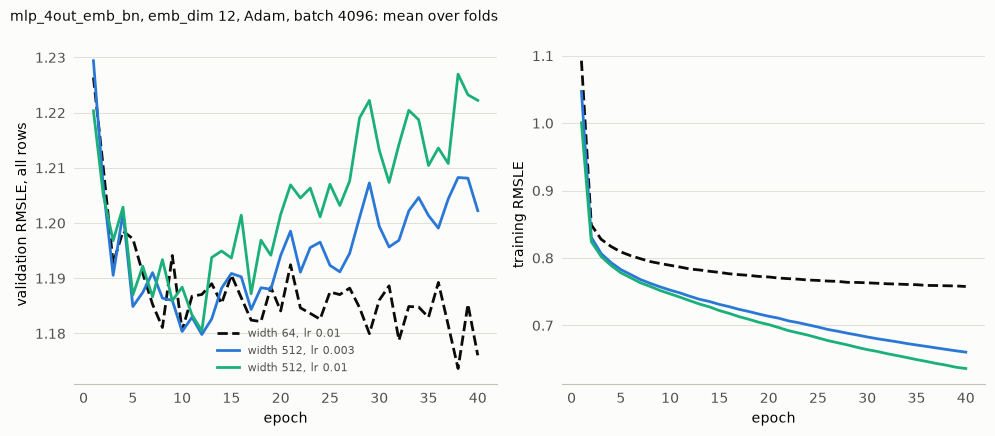

In [5]:
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
STYLES = {  # (width, lr): colour, line style
    (64, 1e-2): (INK, "--"),
    (WIDTH, 1e-2): ("#1baf7a", "-"),
    (WIDTH, LR): ("#2a78d6", "-"),
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), facecolor=SURFACE)
for (width, lr), runs in results.groupby(["width", "lr"]):
    color, ls = STYLES[(width, lr)]
    for ax, key in zip(axes, ["val_curve", "train_curve"]):
        curve = pd.DataFrame(
            runs[key].tolist()
        ).mean()  # mean over folds; a diverged run is shorter
        ax.plot(
            np.arange(1, len(curve) + 1),
            curve,
            lw=2,
            color=color,
            ls=ls,
            label=f"width {width}, lr {lr:g}",
        )
for ax, label in zip(axes, ["validation RMSLE, all rows", "training RMSLE"]):
    ax.set(xlabel="epoch", ylabel=label)
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, lw=0.75)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)
axes[0].legend(frameon=False, fontsize=8, labelcolor=TEXT)
fig.suptitle(
    f"mlp_4out_emb_bn, emb_dim {EMB_DIM}, Adam, batch 4096: mean over folds",
    x=0.01,
    ha="left",
    color=INK,
    fontsize=10,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.query("lr == @LR").run_id:
        experiment.client.log_artifact(run_id, FIGURE)